<a href="https://colab.research.google.com/github/jayy0101/linear_regression_from_scratch/blob/main/linear_regression_from_scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Linear Regression from Scratch (NumPy only)
**Predict house prices using the normal equation and vectorized gradient descent, with no ML library doing the work**

We build the model ourselves from matrix operations, then check it against `scikit-learn` at the end.

| Step | What we build |
|---|---|
| 1 | Seeded housing data generated from a **known formula** (so we can check our answer) |
| 2 | Train/test split and a small toolkit of helper functions |
| 3 | **Normal equation**: check invertibility, then solve with inverse and transpose |
| 4 | **Gradient descent** using the `@` operator, with a loss curve |
| 5 | Evaluation: **RMSE**, **R²**, predicted-vs-actual and residual plots |
| 6 | Compare with `scikit-learn` |
| 7 | Run the same code on a **real dataset** |

**The model:** `price = b + w1*area + w2*bedrooms + w3*age`, or in matrix form `y_hat = X @ w` (with a column of ones in `X` for the bias `b`).

## Step 0: Setup

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)   # reproducible results
print("NumPy", np.__version__)

NumPy 2.1.3


## Step 1: Generate housing data from a known formula
Price (in lakhs) = `20 + 0.05*area + 8*bedrooms - 0.6*age + noise`.
Because we know the true weights, we can check whether our model **recovers** them.

In [ ]:
m = 500   # number of houses

area     = np.random.uniform(500, 3000, m)     # sq ft
bedrooms = np.random.randint(1, 6, m)          # 1 to 5
age      = np.random.uniform(0, 40, m)         # years

X_raw = np.column_stack([area, bedrooms, age])   # shape (500, 3)
feature_names = ["area", "bedrooms", "age"]

true_b = 20.0
true_w = np.array([0.05, 8.0, -0.6])
noise_sd = 10.0
noise = np.random.normal(0, noise_sd, m)

y = X_raw @ true_w + true_b + noise              # shape (500,)

print("X shape:", X_raw.shape, "| y shape:", y.shape)
print("First 3 houses (area, bedrooms, age):\n", X_raw[:3].round(1))
print("First 3 prices (lakhs):", y[:3].round(1))

X shape: (500, 3) | y shape: (500,)
First 3 houses (area, bedrooms, age):
 [[1.4364e+03 1.0000e+00 1.3400e+01]
 [2.8768e+03 1.0000e+00 3.3000e+01]
 [2.3300e+03 1.0000e+00 1.4500e+01]]
First 3 prices (lakhs): [102.7 150.4 151.6]


## Step 2: Toolkit and train/test split
Helper functions we reuse for both the synthetic and the real dataset.

In [ ]:
def add_bias(X):
    '''Prepend a column of ones so the bias b becomes just another weight.'''
    return np.column_stack([np.ones(len(X)), X])

def train_test_split_np(X, y, test_ratio=0.2, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(X))
    cut = int(len(X) * (1 - test_ratio))
    tr, te = idx[:cut], idx[cut:]
    return X[tr], X[te], y[tr], y[te]

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    return 1 - ss_res / ss_tot

def standardize(X_train, X_test):
    '''Scale using TRAIN statistics only (never peek at test data).'''
    mu, sd = X_train.mean(axis=0), X_train.std(axis=0)
    return (X_train - mu) / sd, (X_test - mu) / sd, mu, sd

def gradient_descent(Xb, y, lr=0.1, n_iter=1000):
    m, n = Xb.shape
    w = np.zeros(n)
    history = np.empty(n_iter)
    for i in range(n_iter):
        error = Xb @ w - y                        # (m,)
        history[i] = 0.5 * np.mean(error ** 2)    # cost J(w)
        grad = Xb.T @ error / m                   # (n,)
        w = w - lr * grad
    return w, history

In [ ]:
X_train, X_test, y_train, y_test = train_test_split_np(X_raw, y, test_ratio=0.2, seed=1)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (400, 3) | Test: (100, 3)


## Step 3: The normal equation
Setting the gradient of the cost to zero gives a direct formula:

**w = (XᵀX)⁻¹ Xᵀ y**

It only works if **XᵀX is invertible**. We check the determinant first. (The condition number tells us how numerically safe the inversion is.)

In [ ]:
Xb_train = add_bias(X_train)
Xb_test  = add_bias(X_test)

XtX = Xb_train.T @ Xb_train
print("XtX shape        :", XtX.shape)
print(f"Determinant      : {np.linalg.det(XtX):.3e}   (non-zero -> invertible)")
print(f"Condition number : {np.linalg.cond(XtX):.3e}   (huge -> numerically risky)")

XtX shape        : (4, 4)
Determinant      : 3.809e+18   (non-zero -> invertible)
Condition number : 5.387e+07   (huge -> numerically risky)


In [ ]:
# The formula, written exactly as the math
w_ne = np.linalg.inv(XtX) @ Xb_train.T @ y_train

print("Normal equation result")
print(f"  bias   : {w_ne[0]:8.3f}   (true {true_b})")
for name, est, true in zip(feature_names, w_ne[1:], true_w):
    print(f"  {name:<8}: {est:8.3f}   (true {true})")

Normal equation result
  bias   :   21.426   (true 20.0)
  area    :    0.049   (true 0.05)
  bedrooms:    7.320   (true 8.0)
  age     :   -0.540   (true -0.6)


In [ ]:
# In real work np.linalg.solve is safer than inv: it solves XtX @ w = Xt y directly
w_solve = np.linalg.solve(XtX, Xb_train.T @ y_train)
print("inv() and solve() agree:", np.allclose(w_ne, w_solve))

inv() and solve() agree: True


## Step 4: Gradient descent
Instead of solving directly, start from `w = 0` and repeat:

**w ← w − lr · (1/m) · Xᵀ(Xw − y)**

Gradient descent needs **feature scaling**: `area` is in the thousands but `bedrooms` is 1-5, which makes the cost surface a long narrow valley. We standardize the features (mean 0, std 1) using the **training** statistics.

Cost at start : 7814.49
Cost at end   : 52.40


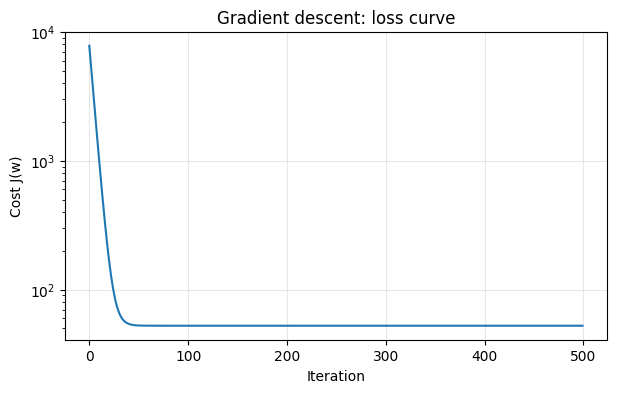

In [ ]:
Xs_train, Xs_test, mu, sd = standardize(X_train, X_test)
Xsb_train, Xsb_test = add_bias(Xs_train), add_bias(Xs_test)

w_gd, history = gradient_descent(Xsb_train, y_train, lr=0.1, n_iter=500)

print(f"Cost at start : {history[0]:.2f}")
print(f"Cost at end   : {history[-1]:.2f}")

plt.figure(figsize=(7, 4))
plt.plot(history)
plt.xlabel("Iteration"); plt.ylabel("Cost J(w)")
plt.title("Gradient descent: loss curve")
plt.yscale("log")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
# The weights above are for STANDARDIZED features. Convert back to original units
# so we can compare with the true weights and the normal equation.
w_gd_orig = w_gd[1:] / sd
b_gd_orig = w_gd[0] - np.sum(w_gd[1:] * mu / sd)

print(f"{'':<10}{'true':>10}{'normal eq':>12}{'grad desc':>12}")
print(f"{'bias':<10}{true_b:>10.3f}{w_ne[0]:>12.3f}{b_gd_orig:>12.3f}")
for i, name in enumerate(feature_names):
    print(f"{name:<10}{true_w[i]:>10.3f}{w_ne[i+1]:>12.3f}{w_gd_orig[i]:>12.3f}")

                true   normal eq   grad desc
bias          20.000      21.426      21.426
area           0.050       0.049       0.049
bedrooms       8.000       7.320       7.320
age           -0.600      -0.540      -0.540


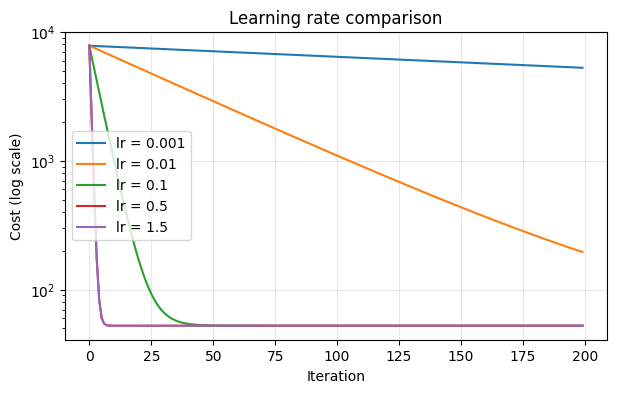

In [ ]:
# Effect of learning rate: too small is slow, too large diverges
fig, ax = plt.subplots(figsize=(7, 4))
for lr in [0.001, 0.01, 0.1, 0.5, 1.5]:
    _, h = gradient_descent(Xsb_train, y_train, lr=lr, n_iter=200)
    ax.plot(np.clip(h, None, 1e5), label=f"lr = {lr}")
ax.set_yscale("log")
ax.set_xlabel("Iteration"); ax.set_ylabel("Cost (log scale)")
ax.set_title("Learning rate comparison")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

## Step 5: Evaluation
- **RMSE**: typical prediction error, in the same units as the target (lakhs here)
- **R²**: fraction of variance explained (1 = perfect, 0 = no better than predicting the mean)

In [ ]:
pred_ne_train = Xb_train @ w_ne
pred_ne_test  = Xb_test  @ w_ne
pred_gd_train = Xsb_train @ w_gd
pred_gd_test  = Xsb_test  @ w_gd

print(f"{'Method':<18}{'Train RMSE':>12}{'Test RMSE':>12}{'Train R2':>10}{'Test R2':>9}")
print("-" * 61)
for name, ptr, pte in [("Normal equation", pred_ne_train, pred_ne_test),
                       ("Gradient descent", pred_gd_train, pred_gd_test)]:
    print(f"{name:<18}{rmse(y_train, ptr):>12.3f}{rmse(y_test, pte):>12.3f}"
          f"{r2_score(y_train, ptr):>10.4f}{r2_score(y_test, pte):>9.4f}")

print(f"\nNoise level we injected: {noise_sd}. A test RMSE near that is the best any model can do.")

Method              Train RMSE   Test RMSE  Train R2  Test R2
-------------------------------------------------------------
Normal equation         10.237       9.914    0.9329   0.9462
Gradient descent        10.237       9.914    0.9329   0.9462

Noise level we injected: 10.0. A test RMSE near that is the best any model can do.


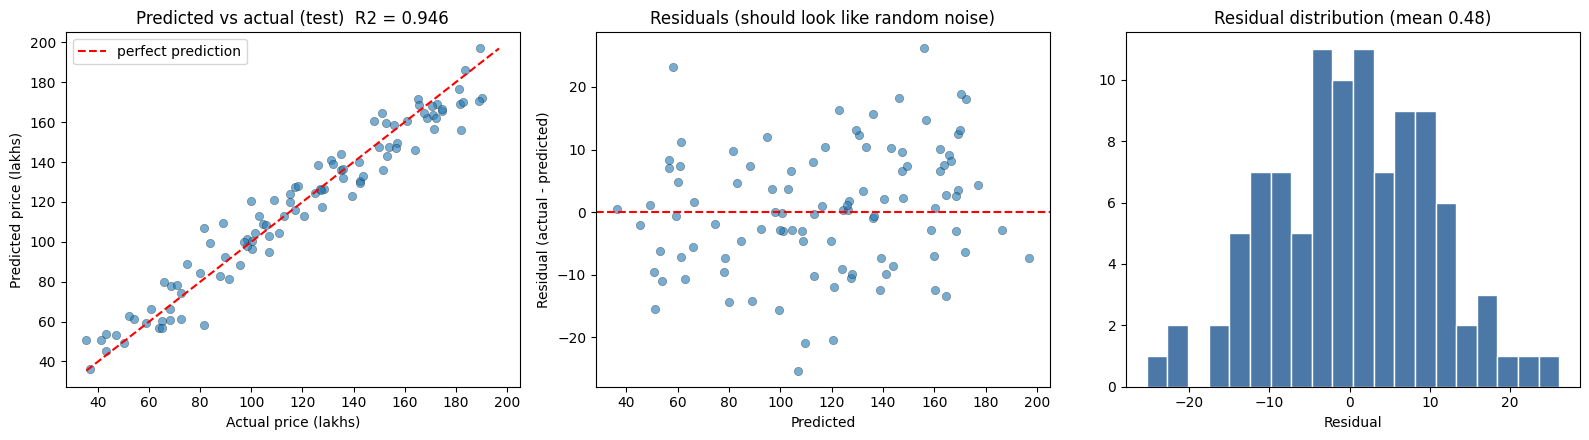

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Predicted vs actual (test set)
axes[0].scatter(y_test, pred_ne_test, alpha=0.6, edgecolor="k", linewidth=0.3)
lims = [min(y_test.min(), pred_ne_test.min()), max(y_test.max(), pred_ne_test.max())]
axes[0].plot(lims, lims, "r--", label="perfect prediction")
axes[0].set_xlabel("Actual price (lakhs)"); axes[0].set_ylabel("Predicted price (lakhs)")
axes[0].set_title(f"Predicted vs actual (test)  R2 = {r2_score(y_test, pred_ne_test):.3f}")
axes[0].legend()

# Residuals vs predicted
resid = y_test - pred_ne_test
axes[1].scatter(pred_ne_test, resid, alpha=0.6, edgecolor="k", linewidth=0.3)
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Residual (actual - predicted)")
axes[1].set_title("Residuals (should look like random noise)")

# Residual histogram
axes[2].hist(resid, bins=20, color="#4C78A8", edgecolor="white")
axes[2].set_title(f"Residual distribution (mean {resid.mean():.2f})")
axes[2].set_xlabel("Residual")

plt.tight_layout()
plt.show()

## Step 6: Check against scikit-learn
If our from-scratch weights match `LinearRegression`, the implementation is correct.

In [ ]:
from sklearn.linear_model import LinearRegression

sk = LinearRegression().fit(X_train, y_train)

print(f"{'':<10}{'ours (NE)':>12}{'ours (GD)':>12}{'sklearn':>12}")
print(f"{'bias':<10}{w_ne[0]:>12.4f}{b_gd_orig:>12.4f}{sk.intercept_:>12.4f}")
for i, name in enumerate(feature_names):
    print(f"{name:<10}{w_ne[i+1]:>12.4f}{w_gd_orig[i]:>12.4f}{sk.coef_[i]:>12.4f}")

print("\nNormal equation matches sklearn:", np.allclose(w_ne[1:], sk.coef_) and np.isclose(w_ne[0], sk.intercept_))
print(f"Test R2 -> ours: {r2_score(y_test, pred_ne_test):.4f} | sklearn: {sk.score(X_test, y_test):.4f}")

             ours (NE)   ours (GD)     sklearn
bias           21.4261     21.4261     21.4261
area            0.0494      0.0494      0.0494
bedrooms        7.3204      7.3204      7.3204
age            -0.5403     -0.5403     -0.5403

Normal equation matches sklearn: True
Test R2 -> ours: 0.9462 | sklearn: 0.9462


## Step 7: A real dataset
Same functions, real data. We try the California housing dataset (median house value in units of $100,000). If it can't be downloaded, the notebook falls back to a dataset bundled with scikit-learn so it always runs.

In [ ]:
try:
    from sklearn.datasets import fetch_california_housing
    data = fetch_california_housing()
    dataset_name = "California housing"
    target_name = "median house value ($100k)"
except Exception as e:
    from sklearn.datasets import load_diabetes
    data = load_diabetes()
    dataset_name = "Diabetes (fallback)"
    target_name = "disease progression score"
    print("Could not download California housing, using fallback:", type(e).__name__)

Xr, yr = data.data, data.target
real_features = list(data.feature_names)
print(f"Dataset: {dataset_name} | X shape {Xr.shape} | target: {target_name}")

Dataset: California housing | X shape (20640, 8) | target: median house value ($100k)


In [ ]:
Xr_train, Xr_test, yr_train, yr_test = train_test_split_np(Xr, yr, test_ratio=0.2, seed=3)
Xrs_train, Xrs_test, mu_r, sd_r = standardize(Xr_train, Xr_test)
Xrb_train, Xrb_test = add_bias(Xrs_train), add_bias(Xrs_test)

# Normal equation (use solve) and gradient descent on the same standardized data
w_r_ne = np.linalg.solve(Xrb_train.T @ Xrb_train, Xrb_train.T @ yr_train)
w_r_gd, hist_r = gradient_descent(Xrb_train, yr_train, lr=0.1, n_iter=1000)

for name, w in [("Normal equation", w_r_ne), ("Gradient descent", w_r_gd)]:
    p_te = Xrb_test @ w
    print(f"{name:<18} test RMSE = {rmse(yr_test, p_te):.4f} | test R2 = {r2_score(yr_test, p_te):.4f}")

sk_r = LinearRegression().fit(Xr_train, yr_train)
print(f"{'scikit-learn':<18} test RMSE = {rmse(yr_test, sk_r.predict(Xr_test)):.4f} | test R2 = {sk_r.score(Xr_test, yr_test):.4f}")

baseline = rmse(yr_test, np.full_like(yr_test, yr_train.mean()))
print(f"{'Baseline (mean)':<18} test RMSE = {baseline:.4f}   <- a model must beat this")

Normal equation    test RMSE = 0.7109 | test R2 = 0.6180
Gradient descent   test RMSE = 0.7108 | test R2 = 0.6180
scikit-learn       test RMSE = 0.7109 | test R2 = 0.6180
Baseline (mean)    test RMSE = 1.1503   <- a model must beat this


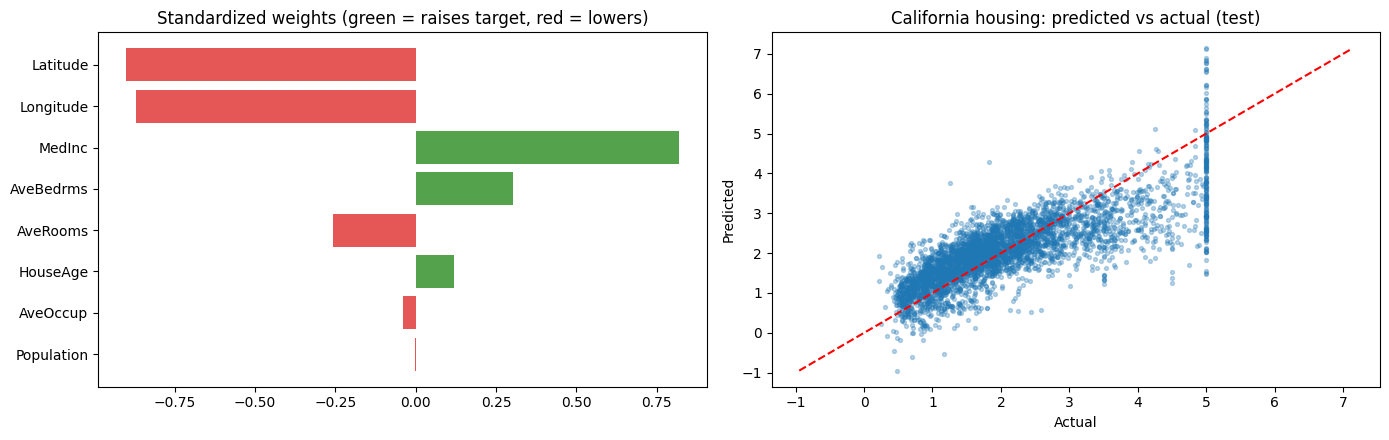

In [ ]:
# Which features matter most? Standardized weights are comparable across features.
coefs = w_r_ne[1:]
order = np.argsort(np.abs(coefs))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].barh(np.array(real_features)[order], coefs[order],
             color=np.where(coefs[order] > 0, "#54A24B", "#E45756"))
axes[0].set_title("Standardized weights (green = raises target, red = lowers)")

p = Xrb_test @ w_r_ne
axes[1].scatter(yr_test, p, alpha=0.3, s=8)
lims = [min(yr_test.min(), p.min()), max(yr_test.max(), p.max())]
axes[1].plot(lims, lims, "r--")
axes[1].set_xlabel("Actual"); axes[1].set_ylabel("Predicted")
axes[1].set_title(f"{dataset_name}: predicted vs actual (test)")
plt.tight_layout()
plt.show()

## Results summary

In [ ]:
print("=== Synthetic housing (500 houses, 3 features) ===")
print(f"Normal equation  test RMSE {rmse(y_test, pred_ne_test):.2f}, R2 {r2_score(y_test, pred_ne_test):.3f}")
print(f"Gradient descent test RMSE {rmse(y_test, pred_gd_test):.2f}, R2 {r2_score(y_test, pred_gd_test):.3f}")
print(f"Matches sklearn: {np.allclose(w_ne[1:], sk.coef_)}")
print()
print(f"=== {dataset_name} ({Xr.shape[0]} rows, {Xr.shape[1]} features) ===")
p = Xrb_test @ w_r_ne
print(f"Normal equation  test RMSE {rmse(yr_test, p):.3f}, R2 {r2_score(yr_test, p):.3f}  (baseline RMSE {baseline:.3f})")

=== Synthetic housing (500 houses, 3 features) ===
Normal equation  test RMSE 9.91, R2 0.946
Gradient descent test RMSE 9.91, R2 0.946
Matches sklearn: True

=== California housing (20640 rows, 8 features) ===
Normal equation  test RMSE 0.711, R2 0.618  (baseline RMSE 1.150)


## What you built
- Generated seeded data from a known formula and **recovered the true weights**
- Implemented the **normal equation** (with an invertibility check) and **vectorized gradient descent** using `@`
- Standardized features with train-only statistics and converted weights back to original units
- Evaluated with **RMSE and R²** on a held-out test set, with predicted-vs-actual and residual plots
- Verified against **scikit-learn**, then ran the same code on a **real dataset**

**Concepts to be ready to explain:**
1. Why gradient descent needs feature scaling (and the normal equation doesn't)
2. What happens when the learning rate is too large (the learning-rate plot)
3. Why we split into train and test, and why scaling uses train statistics only
4. What R² and RMSE mean, and what a baseline model is
5. Normal equation vs gradient descent: the normal equation costs roughly O(n³) in the number of features, while gradient descent scales to large feature counts

**Extend it:** add polynomial features, add L2 regularization (ridge regression), or implement mini-batch gradient descent.